In [2]:
import numpy as np
import sklearn.base
import sklearn.model_selection
import sklearn.metrics
import scipy.stats
import matplotlib.pyplot as plt

from utils import get_random_poly2D_ds

In [3]:
class PolynomialRegression(sklearn.base.BaseEstimator):

    def __init__(self, deg=3):
        self.deg = deg

    def fit(self, x, y):
        self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
        return self

    def predict(self, x):
        return self.poly_(x)

    def score(self, x, y):
        return sklearn.metrics.r2_score(y, self.predict(x))

Funzione Polinomiale:
        5         4         3         2
7.178 x - 2.546 x + 1.103 x + 9.113 x + 4.733 x + 6.324


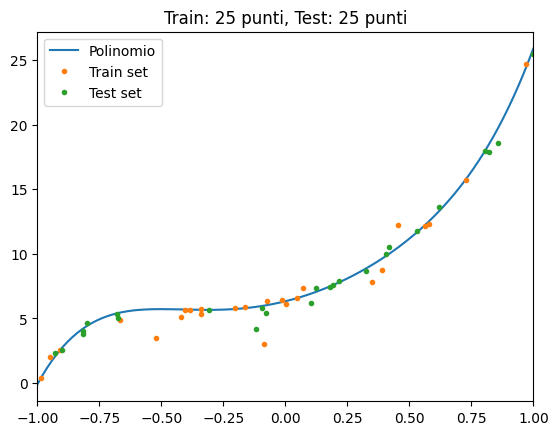

In [4]:
np.random.seed(32)

deg_ds = 5 # Grado del polinomio che vogliamo generare (in questo caso: polinomio di 5° grado)
n = 50    # Numero di campioni che vogliamo generare per il dataset
poly_reg = np.poly1d(np.random.random(deg_ds + 1) * 20 - 10) # Creiamo un polinomio casuale di grado 'deg_ds' con i coefficienti in [-10, 10]

# Stampiamo il polinomio generato in forma leggibile
print("Funzione Polinomiale:\n", poly_reg)


x_train, y_train, x_test, y_test = get_random_poly2D_ds(n, poly_reg, test_size=0.5, to_plot=True)

x_min = np.min(x_train)
x_max = np.max(x_train)

y_min = np.min(y_train)
y_max = np.max(y_train)

x_train = (x_train - x_min) / (x_max - x_min)
y_train = (y_train - y_min) / (y_max - y_min)

x_test = (x_test - x_min) / (x_max - x_min)
y_test = (y_test - y_min) / (y_max - y_min)

In [5]:
print("Grid Search")
gs = sklearn.model_selection.GridSearchCV(cv = 5, estimator = PolynomialRegression(), param_grid={'deg':[1,3,5,25]})
gs = gs.fit(x_train,y_train)

Grid Search


C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))


In [6]:
print("Randomized Search")
rs = sklearn.model_selection.RandomizedSearchCV(cv = 5, n_iter = 15, estimator = PolynomialRegression(), param_distributions={'deg':scipy.stats.randint(1,25)})
rs = rs.fit(x_train,y_train)

Randomized Search


C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(np.polyfit(x, y, deg=self.deg))
C:\Users\Utente\AppData\Local\Temp\ipykernel_18048\3781027310.py:7: RankWarning: Polyfit may be poorly conditioned
  self.poly_ = np.poly1d(

Grid Search: grado = 3
  R2 medio CV:  0.8929
  MSE test:     0.001030
  R2 test:      0.9813

Randomized Search: grado = 3
  R2 medio CV:  0.8929
  MSE test:     0.001030
  R2 test:      0.9813



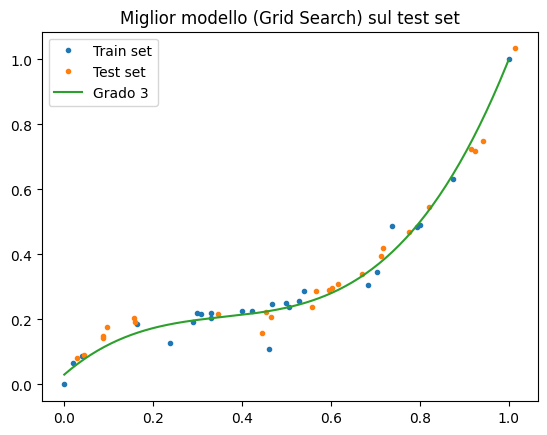

In [7]:
for nome, search in [("Grid Search", gs), ("Randomized Search", rs)]:
    model = search.best_estimator_   # già riaddestrato su tutto il train (refit=True)
    y_pred = model.predict(x_test)

    print(f"{nome}: grado = {search.best_params_['deg']}")
    print(f"{'  R2 medio CV:':<16}{search.best_score_:.4f}")
    print(f"{'  MSE test:':<16}{sklearn.metrics.mean_squared_error(y_test, y_pred):.6f}")
    print(f"{'  R2 test:':<16}{sklearn.metrics.r2_score(y_test, y_pred):.4f}\n")

# Grafico del modello scelto dalla Grid Search
x_plot = np.linspace(x_train.min(), x_train.max(), 200)
plt.plot(x_train, y_train, '.', label="Train set")
plt.plot(x_test, y_test, '.', label="Test set")
plt.plot(x_plot, gs.best_estimator_.predict(x_plot), label=f"Grado {gs.best_params_['deg']}")
plt.legend()
plt.title("Miglior modello (Grid Search) sul test set")
plt.show()